# Predicting Bus Delays for Reliable Public Bus Schedules

## Mission and use case
**Mission:** African cities are urbanizing fast and many people depend on public buses, but there are no public bus schedules, so trips are uncertain. My mission is a platform that publishes precise bus schedules.

**Use case:** A published timetable is only useful if it accounts for delays. This model predicts **how many minutes a bus will be delayed** (`Min Delay`) from the route, time of day, day of week, direction, and type of incident. The schedule platform uses that prediction to publish adjusted arrival times.

**Who uses the prediction and for what:**
- **Commuters** use the adjusted arrival times to plan their trips and decide when to leave.
- **Bus operators and city transport planners** see which routes, hours and incident types cause the longest delays, so they can add buffer time or spare buses.

## Dataset
**TTC Bus Delay Data** (Toronto Transit Commission), City of Toronto Open Data: https://open.toronto.ca/dataset/ttc-bus-delay-data/

Each row is one logged bus delay incident from **January 2025 to September 2026**. African cities do not yet publish bus delay logs like this one, which is the gap my platform is meant to close. This model is the prototype that would run on the same kind of data once the platform collects it from African bus operators.

| Column | Type | Meaning |
|---|---|---|
| Date | date | Day of the incident |
| Line | categorical | Bus route (number and name) |
| Time | time | Time of the incident (HH:MM) |
| Day | categorical | Day of the week |
| Station | categorical | Location of the incident |
| Code | categorical | Incident type code (see `incident_codes.csv`) |
| **Min Delay** | numeric | **Target:** delay in minutes against the schedule |
| Min Gap | numeric | Minutes between this bus and the bus ahead of it |
| Bound | categorical | Direction (N, S, E, W) |
| Vehicle | numeric | Vehicle (bus) number |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("ttc_bus_delay.csv")
codes = pd.read_csv("incident_codes.csv")

df = df.drop(columns=["_id"])  # row index added by the open data portal, not a feature
print("Shape:", df.shape)
df.head()

Shape: (107349, 10)


,Date,Line,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Vehicle
0,2025-01-01T00:00:00,102 MARKHAM ROAD,02:15,Wednesday,WARDEN STATION,MFESA,20,40,N,3442
1,2025-01-01T00:00:00,65 PARLIAMENT,02:15,Wednesday,KIPLING STATION,MFUS,0,0,NaN,0
2,2025-01-01T00:00:00,64 MAIN,02:40,Wednesday,BROADVIEW STATION,MFUI,0,0,NaN,8546
3,2025-01-01T00:00:00,100 FLEMINGDON PARK,02:43,Wednesday,OVERLEA AND THORNCLIFF,MFSAN,17,32,N,8693
4,2025-01-01T00:00:00,34 EGLINTON EAST,03:05,Wednesday,EGLINTON AND DON MILLS,MFUI,20,40,W,8801


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 107349 entries, 0 to 107348
Data columns (total 10 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   Date       107349 non-null  str  
 1   Line       106035 non-null  str  
 2   Time       107349 non-null  str  
 3   Day        107349 non-null  str  
 4   Station    107349 non-null  str  
 5   Code       107349 non-null  str  
 6   Min Delay  107349 non-null  int64
 7   Min Gap    107349 non-null  int64
 8   Bound      84443 non-null   str  
 9   Vehicle    107349 non-null  int64
dtypes: int64(3), str(7)
memory usage: 8.2 MB

Missing values per column:
Date             0
Line          1314
Time             0
Day              0
Station          0
Code             0
Min Delay        0
Min Gap          0
Bound        22906
Vehicle          0
dtype: int64


In [4]:
print("Unique values per column:")
print(df.nunique())
print("\nTarget (Min Delay) summary:")
df["Min Delay"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

Unique values per column:
Date           638
Line           695
Time          1440
Day              7
Station      17018
Code            75
Min Delay      698
Min Gap        741
Bound           17
Vehicle       2787
dtype: int64

Target (Min Delay) summary:


count    107349.000000
mean         21.505687
std          54.632735
min           0.000000
25%           8.000000
50%          12.000000
75%          20.000000
90%          30.000000
99%         261.000000
max         999.000000
Name: Min Delay, dtype: float64

## 1. Exploring the data

To explore numeric relationships, I extract a few helper columns from the raw text and date fields:
- `hour` from `Time`
- `day_of_week` (0 = Monday) and `month` from `Date`
- `route_number` from `Line` (for example `"102 MARKHAM ROAD"` becomes `102`)

The full cleaning and feature engineering happens in Section 2. These columns are only for exploration.

In [5]:
eda = df.copy()
eda["Date"] = pd.to_datetime(eda["Date"])
eda["hour"] = pd.to_datetime(eda["Time"], format="%H:%M").dt.hour
eda["day_of_week"] = eda["Date"].dt.day_of_week
eda["month"] = eda["Date"].dt.month
eda["route_number"] = pd.to_numeric(eda["Line"].str.extract(r"^(\d+)")[0], errors="coerce")
eda[["Line", "route_number", "Time", "hour", "Date", "day_of_week", "month"]].head()

,Line,route_number,Time,hour,Date,day_of_week,month
0,102 MARKHAM ROAD,102.0,02:15,2,2025-01-01,2,1
1,65 PARLIAMENT,65.0,02:15,2,2025-01-01,2,1
2,64 MAIN,64.0,02:40,2,2025-01-01,2,1
3,100 FLEMINGDON PARK,100.0,02:43,2,2025-01-01,2,1
4,34 EGLINTON EAST,34.0,03:05,3,2025-01-01,2,1


### Plot 1: Distribution of the target (`Min Delay`)

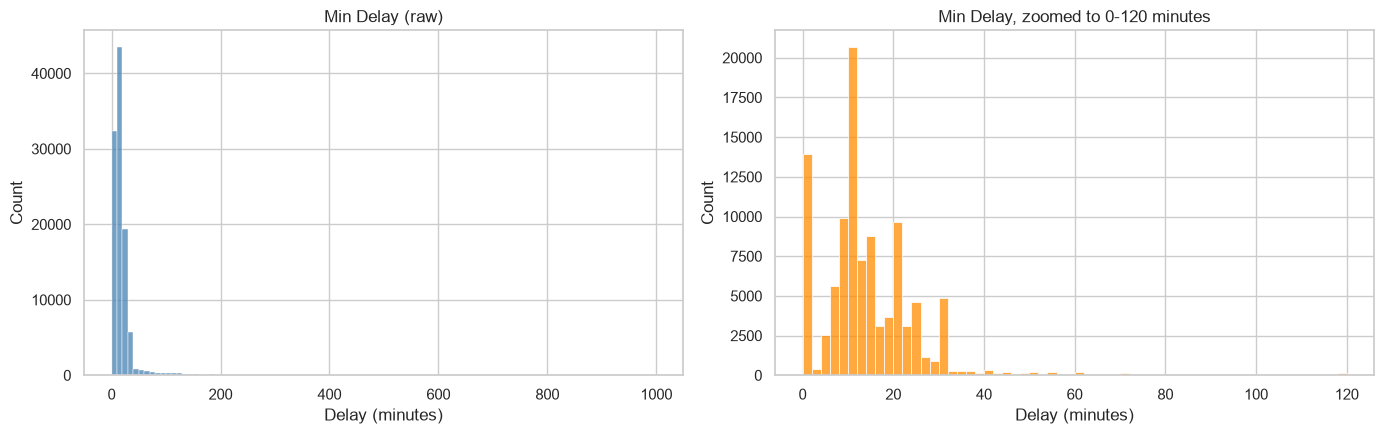

Share of rows with 0-minute delay: 12.8%
Share of rows above 120 minutes:   2.2%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(eda["Min Delay"], bins=100, ax=axes[0], color="steelblue")
axes[0].set_title("Min Delay (raw)")
axes[0].set_xlabel("Delay (minutes)")

sns.histplot(eda.loc[eda["Min Delay"] <= 120, "Min Delay"], bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Min Delay, zoomed to 0-120 minutes")
axes[1].set_xlabel("Delay (minutes)")

plt.tight_layout()
plt.show()

print(f"Share of rows with 0-minute delay: {(eda['Min Delay'] == 0).mean():.1%}")
print(f"Share of rows above 120 minutes:   {(eda['Min Delay'] > 120).mean():.1%}")

**What it shows:** The target is strongly right-skewed. Most delays are between 0 and 30 minutes (median 12, 90th percentile 30), 12.8% of incidents have a 0-minute delay, and a long tail reaches 999 minutes. Only about 2% of rows are above 120 minutes, and values like 999 look like placeholder entries rather than real delays.

**Decision:** In cleaning I will remove extreme outliers (very long delays) so that a few rare, multi-hour disruptions do not dominate the squared-error loss, because MSE punishes large errors heavily. The model will target everyday delays, which are what a published schedule needs to adjust for.

### Plot 2: Correlation heatmap of the numeric columns

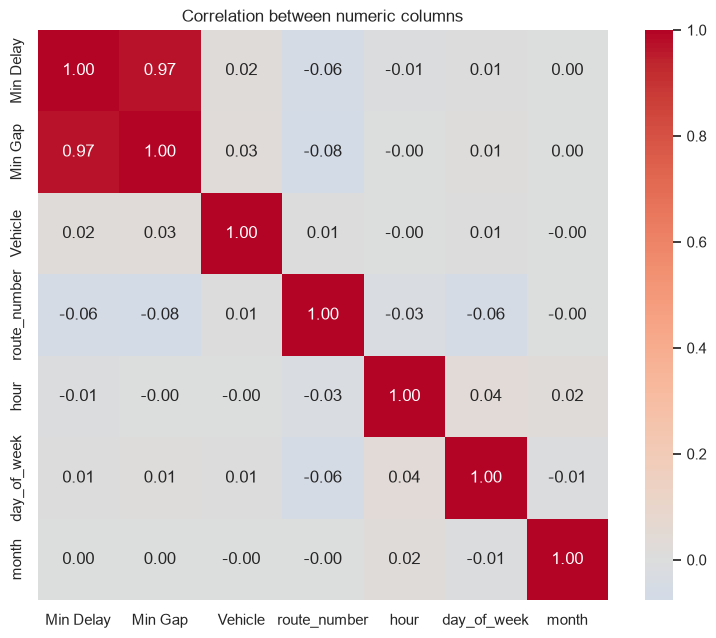

Min Gap         0.969015
route_number   -0.055661
Vehicle         0.019560
hour           -0.010884
day_of_week     0.006873
month           0.003126
Name: Min Delay, dtype: float64

In [7]:
num_cols = ["Min Delay", "Min Gap", "Vehicle", "route_number", "hour", "day_of_week", "month"]
corr = eda[num_cols].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

corr["Min Delay"].drop("Min Delay").sort_values(key=abs, ascending=False)

**What it shows:** `Min Gap` is almost perfectly correlated with the target (0.97). Every other numeric column (`Vehicle`, `route_number`, `hour`, `day_of_week`, `month`) has a correlation close to 0 with `Min Delay`, so none of them has a strong *linear* relationship with delay on its own.

**Decision:** `Min Gap` is too good to be a fair feature, so Plot 3 checks it for leakage. Because the remaining numeric columns are weak linear predictors, the categorical columns (incident type, route, direction) will have to carry most of the signal, so they must be encoded carefully. I also expect tree-based models to beat the linear ones, since they can capture non-linear effects such as particular hours or routes.

### Plot 3: `Min Gap` vs `Min Delay` (checking for leakage)

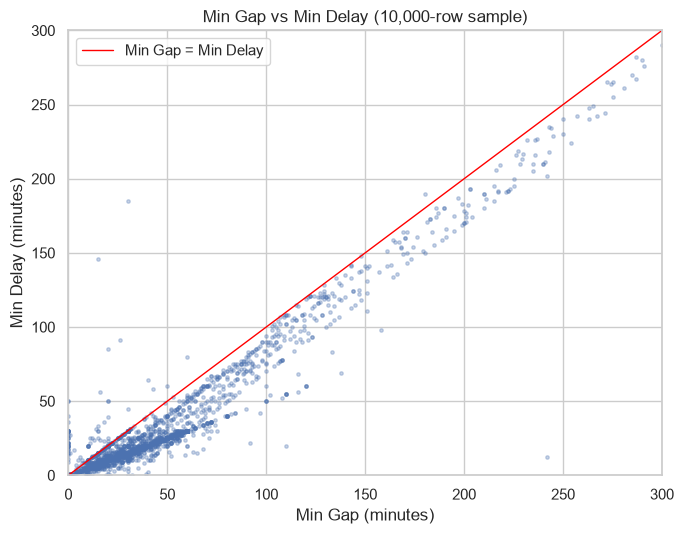

Rows where Min Gap >= Min Delay: 99.3%


In [8]:
sample = eda.sample(10_000, random_state=RANDOM_STATE)

plt.figure(figsize=(7, 5.5))
plt.scatter(sample["Min Gap"], sample["Min Delay"], s=6, alpha=0.3)
lim = 300
plt.plot([0, lim], [0, lim], color="red", lw=1, label="Min Gap = Min Delay")
plt.xlim(0, lim); plt.ylim(0, lim)
plt.xlabel("Min Gap (minutes)")
plt.ylabel("Min Delay (minutes)")
plt.title("Min Gap vs Min Delay (10,000-row sample)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Rows where Min Gap >= Min Delay: {(eda['Min Gap'] >= eda['Min Delay']).mean():.1%}")

**What it shows:** Almost every point lies on or just below the line `Min Gap = Min Delay`. In 99.3% of rows the gap is at least the delay, because the gap is the scheduled gap plus the delay itself. `Min Gap` is only known *after* the delay has happened.

**Decision:** I drop `Min Gap`. Keeping it would leak the answer into the inputs: the model would look excellent in the notebook but be useless in the app, where we want to predict the delay *before* it is known. Dropping it lowers the scores but makes the model honest.

### Plot 4: How the categorical columns affect the delay

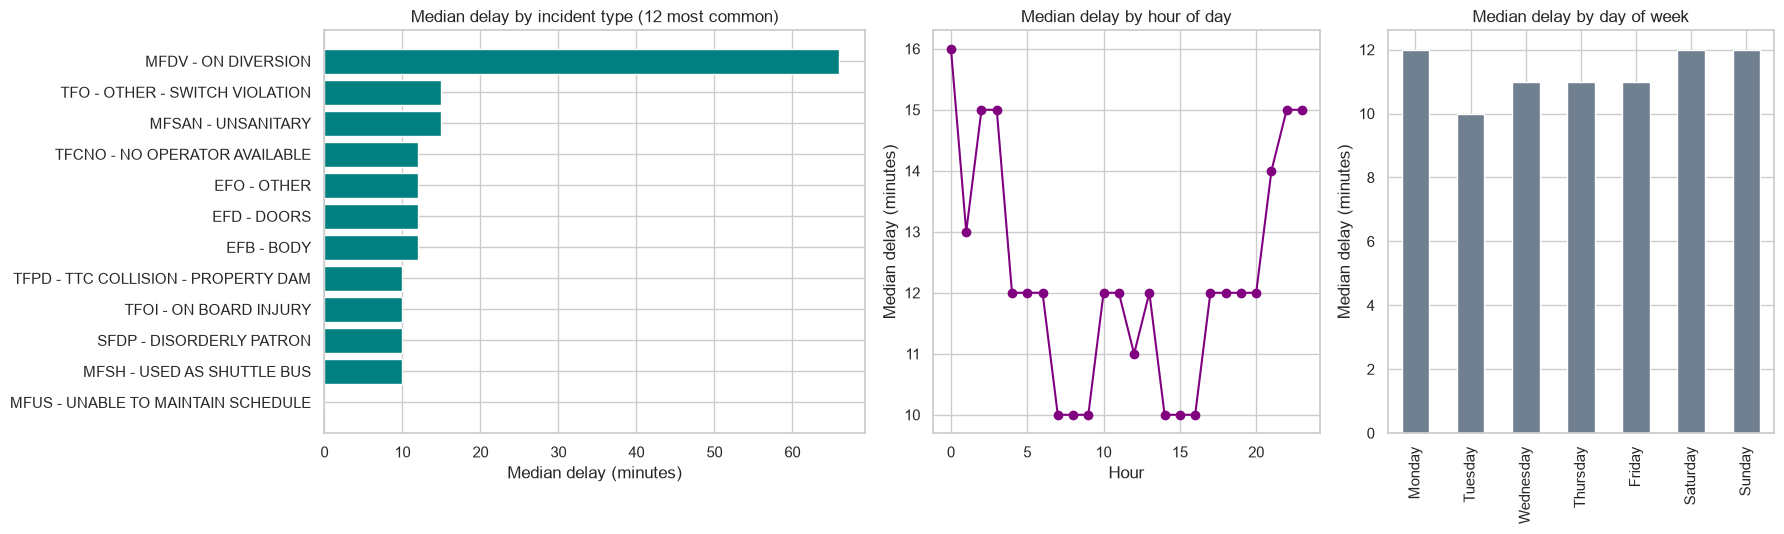

In [9]:
# the descriptions file stores some dashes as broken characters, so replace any non-ASCII run with "-"
codes["DESCRIPTION"] = codes["DESCRIPTION"].str.replace(r"[^\x20-\x7E]+", "-", regex=True)
code_desc = dict(zip(codes["CODE"], codes["DESCRIPTION"]))
top_codes = eda["Code"].value_counts().head(12).index

by_code = (eda[eda["Code"].isin(top_codes)]
           .groupby("Code")["Min Delay"].median()
           .sort_values())
labels = [f"{c} - {code_desc.get(c, 'unknown')[:28]}" for c in by_code.index]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.4, 1, 1]})

axes[0].barh(labels, by_code.values, color="teal")
axes[0].set_title("Median delay by incident type (12 most common)")
axes[0].set_xlabel("Median delay (minutes)")

eda.groupby("hour")["Min Delay"].median().plot(ax=axes[1], marker="o", color="purple")
axes[1].set_title("Median delay by hour of day")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("Median delay (minutes)")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
eda.groupby("Day")["Min Delay"].median().reindex(day_order).plot.bar(ax=axes[2], color="slategray")
axes[2].set_title("Median delay by day of week")
axes[2].set_xlabel(""); axes[2].set_ylabel("Median delay (minutes)")

plt.tight_layout()
plt.show()

**What it shows:** The incident type matters most. Buses **on diversion** (`MFDV`) have a median delay of about 66 minutes, against 10 to 15 minutes for most other incident types, and "unable to maintain schedule" (`MFUS`) has a median of 0. Delays are also longer late at night (about 15 to 16 minutes around midnight versus 10 in the morning and afternoon peaks), while the day of the week changes the median only slightly (10 to 12 minutes).

**Decision:** `Code` (incident type) will be one of the most important features, so I keep it and encode it. I also keep `hour` and the day of the week, adding a weekend/weekday flag, because they show small but real patterns. These effects are non-linear (the hourly curve is U-shaped), which supports trying tree-based models alongside the linear ones.

## 2. Data cleaning and feature engineering

### 2.1 Columns dropped and why

| Column | Why it is dropped |
|---|---|
| `_id` | Row number added by the open data portal, not information about the bus (already dropped on load) |
| `Min Gap` | **Leaks the target** (Plot 3): it includes the delay itself and is only known after the delay happens |
| `Station` | 17,018 unique free-text locations with inconsistent spelling (for example "KIPLING STN" vs "KIPLING STATION"). Too many to encode, and too noisy to type into an app |
| `Vehicle` | An ID number (bus fleet number), not a quantity. A bigger number does not mean anything for delay (correlation 0.02) |
| `Day` | Same information as `Date`; replaced by the numeric `day_of_week` |
| `Date`, `Time`, `Line` | Replaced by the cleaner numeric features extracted from them (`month`, `day_of_week`, `hour`, `route_number`) |

### 2.2 Cleaning the rows

Each step prints how many rows remain:
1. Remove exact duplicate rows.
2. Remove rows with no route (`Line` missing), and keep only real bus route numbers (1 to 999). Values like `9999` or text such as `"LINE 1 SHUTTLE"` are subway replacement shuttles or data entry errors.
3. Keep only rows with a valid direction (N, S, E or W). About 21% have no direction recorded. A schedule is always published for a known direction, so these rows cannot be used.
4. Remove extreme delays above **120 minutes** (about 2% of rows, Plot 1). These are multi-hour service disruptions or placeholder values like 999, not delays a timetable can absorb. Because MSE squares errors, keeping them would let a few rare rows dominate training.

In [10]:
clean = df.copy()
print(f"Start:                              {len(clean):>7,} rows")

clean = clean.drop_duplicates()
print(f"After removing duplicates:          {len(clean):>7,} rows")

clean["route_number"] = pd.to_numeric(clean["Line"].str.extract(r"^(\d+)")[0], errors="coerce")
clean = clean[clean["route_number"].between(1, 999)]
clean["route_number"] = clean["route_number"].astype(int)
print(f"After keeping valid routes (1-999): {len(clean):>7,} rows")

clean = clean[clean["Bound"].isin(["N", "S", "E", "W"])]
print(f"After keeping valid directions:     {len(clean):>7,} rows")

MAX_DELAY = 120
clean = clean[clean["Min Delay"] <= MAX_DELAY]
print(f"After removing delays > {MAX_DELAY} min:   {len(clean):>7,} rows")

Start:                              107,349 rows
After removing duplicates:          107,049 rows
After keeping valid routes (1-999): 105,273 rows
After keeping valid directions:      83,684 rows
After removing delays > 120 min:    81,967 rows


### 2.3 Feature engineering

New features created from the raw columns:
- `hour` (0 to 23) from `Time`
- `day_of_week` (0 = Monday to 6 = Sunday) and `month` (1 to 12) from `Date`
- `is_weekend`: 1 on Saturday or Sunday. Weekend service runs on a different timetable.
- `is_night`: 1 between 21:00 and 04:59. Plot 4 showed delays are longer at night, when fewer buses run.
- `incident_code`: the incident `Code`, with codes seen fewer than 100 times grouped into `"OTHER"`. The kept codes cover about 99% of rows (printed below), so rare codes would only add noise and could not be learned reliably.
- `direction`: the cleaned `Bound` column.

In [11]:
clean["Date"] = pd.to_datetime(clean["Date"])
clean["hour"] = pd.to_datetime(clean["Time"], format="%H:%M").dt.hour
clean["day_of_week"] = clean["Date"].dt.day_of_week
clean["month"] = clean["Date"].dt.month
clean["is_weekend"] = (clean["day_of_week"] >= 5).astype(int)
clean["is_night"] = ((clean["hour"] >= 21) | (clean["hour"] < 5)).astype(int)

code_counts = clean["Code"].value_counts()
KNOWN_CODES = sorted(code_counts[code_counts >= 100].index)
clean["incident_code"] = clean["Code"].where(clean["Code"].isin(KNOWN_CODES), "OTHER")
clean["direction"] = clean["Bound"]

CATEGORICAL = ["route_number", "direction", "incident_code"]
NUMERIC = ["hour", "day_of_week", "month", "is_weekend", "is_night"]
FEATURES = CATEGORICAL + NUMERIC
TARGET = "Min Delay"

data = clean[FEATURES + [TARGET]].reset_index(drop=True)
print("Final shape:", data.shape)
print(f"Incident codes kept: {len(KNOWN_CODES)} (+ OTHER), covering {(clean['incident_code'] != 'OTHER').mean():.1%} of rows")
data.head()

Final shape: (81967, 9)
Incident codes kept: 41 (+ OTHER), covering 98.6% of rows


,route_number,direction,incident_code,hour,day_of_week,month,is_weekend,is_night,Min Delay
0,102,N,MFESA,2,2,1,0,1,20
1,100,N,MFSAN,2,2,1,0,1,17
2,34,W,MFUI,3,2,1,0,1,20
3,307,N,MFUS,3,2,1,0,1,0
4,320,N,MFSAN,3,2,1,0,1,5


**Final features (8):**

| Feature | Type | Values |
|---|---|---|
| `route_number` | categorical | bus route, for example 29 or 102 |
| `direction` | categorical | N, S, E, W |
| `incident_code` | categorical | incident type code, for example MFDV (on diversion) |
| `hour` | numeric | 0 to 23 |
| `day_of_week` | numeric | 0 (Mon) to 6 (Sun) |
| `month` | numeric | 1 to 12 |
| `is_weekend` | numeric (0/1) | derived from `day_of_week` |
| `is_night` | numeric (0/1) | derived from `hour` |

`route_number` is stored as a number but treated as **categorical**: route 100 is not "bigger" than route 29, just a different road.

### 2.4 Converting categorical columns to numeric

The categorical columns have no natural order, so I use **one-hot encoding**: every category becomes its own 0/1 column. For example, `direction = "N"` becomes `direction_N = 1, direction_S = 0, direction_E = 0, direction_W = 0`. Label encoding (N=0, S=1, ...) would wrongly tell the linear models that "W" is three times "S".

Below, `pd.get_dummies` shows the encoded matrix and measures which features matter most. For the models, the same encoding is done by scikit-learn's `OneHotEncoder` inside a `Pipeline` (Section 3), so the saved model can take raw values such as `"N"` or `"MFDV"` straight from the API.

In [12]:
encoded = pd.get_dummies(data[FEATURES], columns=CATEGORICAL, dtype=int)
print("Before encoding:", data[FEATURES].shape, "->  after one-hot encoding:", encoded.shape)
print("All columns numeric:", encoded.dtypes.apply(lambda t: np.issubdtype(t, np.number)).all())
encoded.iloc[:5, :12]

Before encoding: (81967, 8) ->  after one-hot encoding: (81967, 296)
All columns numeric: True


,hour,day_of_week,month,is_weekend,is_night,route_number_1,route_number_7,route_number_8,route_number_9,route_number_10,route_number_11,route_number_12
0,2,2,1,0,1,0,0,0,0,0,0,0
1,2,2,1,0,1,0,0,0,0,0,0,0
2,3,2,1,0,1,0,0,0,0,0,0,0
3,3,2,1,0,1,0,0,0,0,0,0,0
4,3,2,1,0,1,0,0,0,0,0,0,0


### Plot 5: Which features matter most for the delay

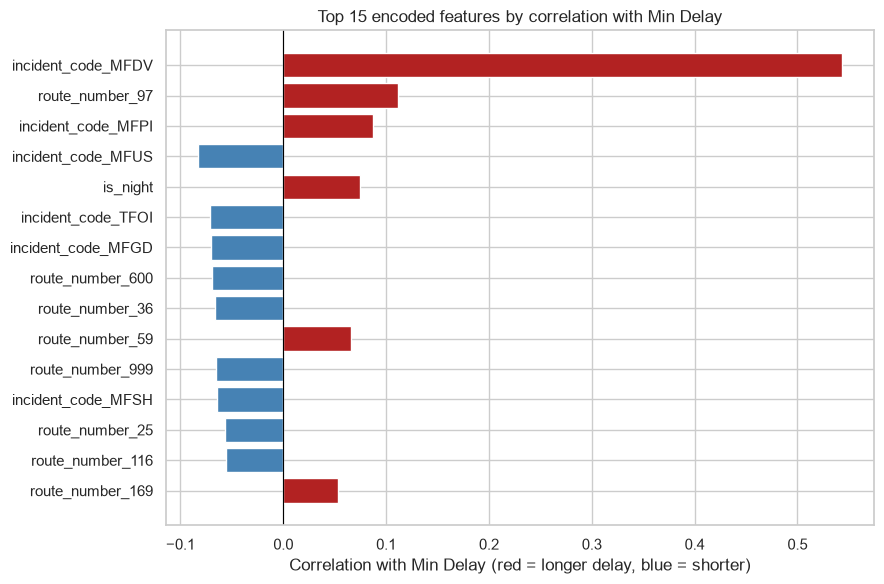

incident_code_MFDV    0.543
route_number_97       0.111
incident_code_MFPI    0.087
incident_code_MFUS   -0.083
is_night              0.074
incident_code_TFOI   -0.071
incident_code_MFGD   -0.070
route_number_600     -0.069
route_number_36      -0.067
route_number_59       0.066
route_number_999     -0.066
incident_code_MFSH   -0.064
route_number_25      -0.057
route_number_116     -0.056
route_number_169      0.053
dtype: float64

In [13]:
feature_corr = encoded.corrwith(data[TARGET]).dropna()
top = feature_corr.reindex(feature_corr.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(9, 6))
colors = ["firebrick" if v > 0 else "steelblue" for v in top.values]
plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
plt.axvline(0, color="black", lw=0.8)
plt.title("Top 15 encoded features by correlation with Min Delay")
plt.xlabel("Correlation with Min Delay (red = longer delay, blue = shorter)")
plt.tight_layout()
plt.show()

top.round(3)

**What it shows:** `incident_code_MFDV` (bus **on diversion**) is by far the most important feature, with a correlation of 0.54 with the delay. Every other feature is below 0.12. Next come a few specific routes (route 97 runs longer, while routes like 36 and 600 run shorter), other incident types (MFPI, collisions with injury, raise the delay; MFUS, "unable to maintain schedule", lowers it), and `is_night` (0.07), the strongest time feature. `hour`, `day_of_week` and `month` on their own are weak.

**Most important features for the target:** 1) incident type, 2) route, 3) time of day (night vs day). Direction, day of week and month add a little each.

**Decision:** I keep all 8 features. The incident type and route carry most of the signal, and the time features add small effects that combine with them (for example, a diversion at night). Because one feature dominates and the rest act in small, non-linear combinations, I expect the linear models to capture only part of the variation and the tree-based models to do better.

## 3. Train/test split and standardization

I split the data into **80% training and 20% test** with a fixed random seed, so every model is evaluated on exactly the same test rows.

The preprocessing is then **fitted on the training set only** and applied to both sets:
- **Categorical columns** (`route_number`, `direction`, `incident_code`) are one-hot encoded. `handle_unknown="ignore"` means a route or code never seen in training becomes all zeros instead of crashing the API.
- **Numeric columns** (`hour`, `day_of_week`, `month`, `is_weekend`, `is_night`) are standardized with `StandardScaler` to mean 0 and standard deviation 1. Gradient descent (SGD) needs this: without scaling, a feature like `month` (1 to 12) would take much bigger steps than a 0/1 feature, and training would be unstable.

Fitting the scaler on the training set only keeps the test set truly unseen. If the scaler saw the test data, its mean and standard deviation would leak information about the test rows into training.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")

Train: 65,573 rows | Test: 16,394 rows


In [15]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ("numeric", StandardScaler(), NUMERIC),
])

# fit on the TRAINING set only, then apply the same transformation to both sets
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Encoded + scaled shape -> train:", X_train_prep.shape, "| test:", X_test_prep.shape)

# check: the scaled numeric columns have mean ~0 and std ~1 on the training set
n_num = len(NUMERIC)
check = pd.DataFrame({
    "train mean": X_train_prep[:, -n_num:].mean(axis=0),
    "train std": X_train_prep[:, -n_num:].std(axis=0),
    "test mean": X_test_prep[:, -n_num:].mean(axis=0),
}, index=NUMERIC).round(3)
check

Encoded + scaled shape -> train: (65573, 292) | test: (16394, 292)


,train mean,train std,test mean
hour,-0.0,1.0,-0.014
day_of_week,-0.0,1.0,-0.007
month,0.0,1.0,-0.005
is_weekend,0.0,1.0,-0.009
is_night,-0.0,1.0,-0.010


## 4. Training and comparing the four models

All four models use scikit-learn and are scored with **mean squared error (MSE)** on the same test set. As a reference point, I also compute the MSE of a "model" that always predicts the average training delay. Any useful model has to beat it.

These are first versions with sensible default settings. `SGDRegressor` is tuned in Section 5.

| Model | Settings | Why |
|---|---|---|
| `SGDRegressor` | squared-error loss, L2 penalty, `eta0=0.01`, up to 1,000 epochs | Linear regression by gradient descent (main model) |
| `LinearRegression` | closed form (least squares) | Exact linear solution to compare SGD against |
| `DecisionTreeRegressor` | `min_samples_leaf=100` | Every leaf must hold at least 100 trips, so the tree cannot memorize single rows |
| `RandomForestRegressor` | 100 trees, `max_features="sqrt"`, `min_samples_leaf=5` | Averages many different trees to reduce the variance of a single tree |

**How I chose the tree settings:** I tried a few settings and kept the ones with the lowest test error that train in seconds. A depth limit of 12 underfit (test MSE about 129), so letting the tree grow but requiring 100 trips per leaf worked better. My first forest (200 trees, all features at every split) took over 5 minutes to train and overfit (train MSE 70 vs test 110). `max_features="sqrt"` makes each split look at a random subset of features, so the trees differ more from each other: the forest trains about 30 times faster, generalizes better, and the saved file stays small enough for GitHub and Render.

In [16]:
import time
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline (always predict the mean = {y_train.mean():.1f} min): test MSE = {baseline_mse:.2f}")

Baseline (always predict the mean = 15.5 min): test MSE = 198.42


In [17]:
models = {
    "SGDRegressor (gradient descent)": SGDRegressor(
        loss="squared_error", penalty="l2", alpha=0.0001, eta0=0.01,
        max_iter=1000, tol=1e-4, random_state=RANDOM_STATE),
    "LinearRegression (closed form)": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        min_samples_leaf=100, random_state=RANDOM_STATE),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=100, max_features="sqrt", min_samples_leaf=5,
        n_jobs=-1, random_state=RANDOM_STATE),
}

results = []
for name, model in models.items():
    start = time.time()
    model.fit(X_train_prep, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train_prep))
    test_mse = mean_squared_error(y_test, model.predict(X_test_prep))
    results.append({"Model": name, "Train MSE": train_mse, "Test MSE": test_mse})
    print(f"{name:<33} train MSE {train_mse:7.2f} | test MSE {test_mse:7.2f} | {time.time() - start:5.1f}s")

SGDRegressor (gradient descent)   train MSE  109.20 | test MSE  109.23 |   4.2s


LinearRegression (closed form)    train MSE  108.58 | test MSE  108.83 |   1.0s


DecisionTreeRegressor             train MSE  109.91 | test MSE  114.02 |   5.8s


RandomForestRegressor             train MSE  101.47 | test MSE  107.86 |  10.3s


In [18]:
first_results = pd.DataFrame(results).set_index("Model")
first_results["Test RMSE (min)"] = np.sqrt(first_results["Test MSE"])
first_results.round(2)

,Train MSE,Test MSE,Test RMSE (min)
Model,,,
SGDRegressor (gradient descent),109.20,109.23,10.45
LinearRegression (closed form),108.58,108.83,10.43
DecisionTreeRegressor,109.91,114.02,10.68
RandomForestRegressor,101.47,107.86,10.39


**What the first results show:**
- **All four models beat the baseline** (test MSE 198 to about 108, roughly 45% lower). A typical error is about **10.4 minutes** (RMSE), against delays that average 15.5 minutes.
- **The two linear models are almost identical** (SGD 109.2 vs closed form 108.8). This is expected: gradient descent converges towards the same least-squares solution that `LinearRegression` computes exactly. Their train and test MSE are almost equal, so they **do not overfit**, but they are limited (high bias): a straight-line model can only add up separate effects (+X minutes for a diversion, +Y for route 97) and cannot learn combinations such as "diversion at night on route 97".
- **The single decision tree is the weakest on the test set** (114.0), with a gap between train and test: one tree splits the data into fixed groups and is sensitive to noise. With 292 one-hot columns, each split can only separate one route or one code at a time, which makes it hard for one tree to use the categories well.
- **The random forest has the lowest test MSE (107.9)**, because averaging 100 different trees cancels much of the single tree's noise. It also has the largest train/test gap (101.5 vs 107.9), so it overfits slightly.

**How the dataset shapes these results:** The models end up close together because of the data. Most of the explainable variation comes from one strong feature (being on diversion), which even a linear model captures as a simple shift. The rest of a delay depends on things the dataset does not record, such as traffic, weather or how serious the incident was, so no model can reduce the error far below about 10 minutes. The non-linear models gain only a little on top of the linear ones.

**Next:** Section 5 tunes `SGDRegressor` (learning rate, regularization, epochs) and plots its loss curve.

## 5. Tuning the SGDRegressor (linear regression by gradient descent)

I tune three hyperparameters:
- **Learning rate** (`eta0`, with `learning_rate="constant"` so the step size stays fixed and its effect is easy to see): how big each gradient descent step is.
- **Regularization strength** (`alpha`, L2 penalty): how strongly large weights are penalized.
- **Number of epochs** (`max_iter`, with `tol=None` so training runs for exactly that many passes over the data).

**I tune on a validation set, not the test set.** I split off 20% of the *training* data as a validation set, so the test set stays untouched until the final comparison. Choosing settings by test MSE would make the final test score too optimistic. The preprocessor for this step is again fitted only on the part used for training.

I tune one hyperparameter at a time: first the learning rate, then `alpha` with the best learning rate, then the number of epochs with both. Each step keeps the value with the lowest validation MSE.

In [19]:
import warnings
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # expected: tol=None runs a fixed number of epochs

X_sub, X_val, y_sub, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
tuning_prep = clone(preprocessor)
X_sub_prep = tuning_prep.fit_transform(X_sub)   # fitted on the sub-training part only
X_val_prep = tuning_prep.transform(X_val)
print(f"Sub-train: {len(X_sub):,} rows | Validation: {len(X_val):,} rows")

def evaluate_sgd(eta0, alpha, epochs):
    model = SGDRegressor(loss="squared_error", penalty="l2", learning_rate="constant",
                         eta0=eta0, alpha=alpha, max_iter=epochs, tol=None,
                         random_state=RANDOM_STATE)
    model.fit(X_sub_prep, y_sub)
    return (mean_squared_error(y_sub, model.predict(X_sub_prep)),
            mean_squared_error(y_val, model.predict(X_val_prep)))

def sweep(name, values, **fixed):
    rows = []
    for v in values:
        train_mse, val_mse = evaluate_sgd(**{**fixed, name: v})
        rows.append({name: v, "Train MSE": train_mse, "Validation MSE": val_mse})
    table = pd.DataFrame(rows)
    best = table.loc[table["Validation MSE"].idxmin(), name]
    return table, best

Sub-train: 52,458 rows | Validation: 13,115 rows


In [20]:
# 1) learning rate (alpha and epochs fixed)
lr_table, best_eta0 = sweep("eta0", [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05], alpha=1e-4, epochs=30)

# 2) regularization strength (best learning rate, epochs fixed)
alpha_table, best_alpha = sweep("alpha", [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1], eta0=best_eta0, epochs=30)

# 3) number of epochs (best learning rate and alpha)
epoch_table, best_epochs = sweep("epochs", [1, 5, 10, 25, 50, 100], eta0=best_eta0, alpha=best_alpha)

best_epochs = int(best_epochs)
print(f"Best learning rate (eta0): {best_eta0}")
print(f"Best alpha:                {best_alpha}")
print(f"Best number of epochs:     {best_epochs}")

Best learning rate (eta0): 0.001
Best alpha:                0.0
Best number of epochs:     100


### Plot 6: Effect of each hyperparameter on the loss

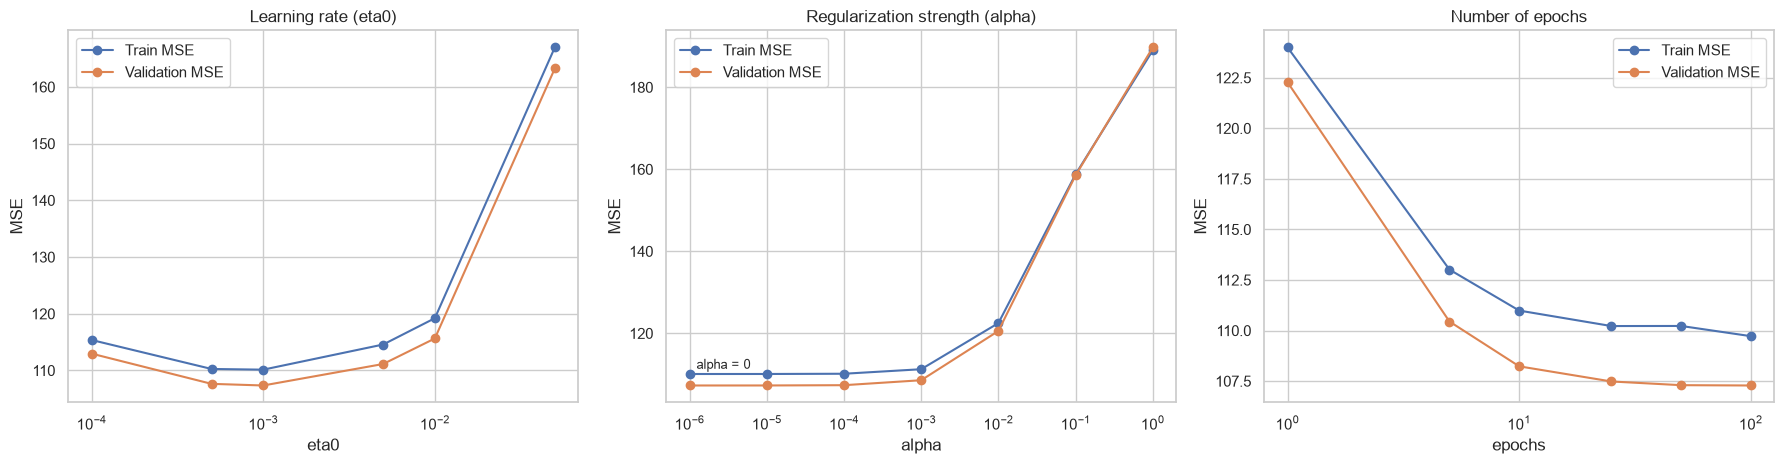

eta0,Train MSE,Validation MSE
0.000100,115.37,112.97
0.000500,110.26,107.64
0.001000,110.14,107.35
0.005000,114.58,111.14
0.010000,119.21,115.64
0.050000,166.98,163.26


alpha,Train MSE,Validation MSE
0.000000,110.08,107.28
0.000010,110.08,107.28
0.000100,110.14,107.35
0.001000,111.24,108.56
0.010000,122.49,120.57
0.100000,158.81,158.54
1.000000,189.02,189.73


epochs,Train MSE,Validation MSE
1,124.00,122.28
5,113.01,110.45
10,110.99,108.23
25,110.22,107.48
50,110.23,107.30
100,109.72,107.28


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (table, col, title) in zip(axes, [
        (lr_table, "eta0", "Learning rate (eta0)"),
        (alpha_table, "alpha", "Regularization strength (alpha)"),
        (epoch_table, "epochs", "Number of epochs")]):
    x = table[col].replace(0, 1e-6) if col == "alpha" else table[col]  # show alpha=0 on the log axis
    ax.plot(x, table["Train MSE"], marker="o", label="Train MSE")
    ax.plot(x, table["Validation MSE"], marker="o", label="Validation MSE")
    ax.set_xscale("log")
    ax.set_title(title); ax.set_xlabel(col); ax.set_ylabel("MSE")
    ax.legend()
axes[1].annotate("alpha = 0", (1e-6, alpha_table["Validation MSE"].iloc[0]),
                 textcoords="offset points", xytext=(5, 12), fontsize=9)
plt.tight_layout()
plt.show()

fmt = {"Train MSE": "{:.2f}", "Validation MSE": "{:.2f}"}
display(lr_table.style.format(fmt).hide(axis="index"),
        alpha_table.style.format(fmt).hide(axis="index"),
        epoch_table.style.format(fmt).hide(axis="index"))

**How each hyperparameter changed the loss:**
- **Learning rate:** U-shaped. Too small (`0.0001`) and the steps are so tiny that after 30 epochs the model has not reached the minimum yet (validation MSE 113.0). Too large (`0.01`, `0.05`) and the steps overshoot and bounce around the minimum, so the loss gets worse fast (163.3 at `0.05`). **`0.001` gave the lowest validation MSE (107.35).**
- **Regularization (`alpha`):** Values from 0 to `0.0001` give the same loss (about 107.3). From `0.001` upwards the penalty shrinks the useful weights (like the +34 minutes for a diversion) and the loss rises sharply, to 189.7 at `alpha = 1`, about as bad as always predicting the mean. The model is not overfitting (train and validation MSE are almost equal), so regularization has nothing to fix here and only hurts when it is strong. **Best: `alpha = 0`** (`1e-5` is practically identical).
- **Epochs:** One epoch is not enough (122.3). The loss drops quickly up to about 10 epochs, then flattens: 25, 50 and 100 epochs all give about 107.3 to 107.5. **100 epochs had the lowest value**, but most of the gain is reached by about 25.

**Overall:** tuning brought SGD from badly configured settings (MSE 120 to 190) down to the floor of a linear model. Every reasonable setting ends close to the closed-form `LinearRegression` result, which is the best a straight-line model can reach on these features. The small differences left (below 0.5 MSE) are noise from the random order of the gradient steps.

### Plot 7: Loss curve of the tuned SGDRegressor

scikit-learn does not record the loss per epoch, so I train the tuned model myself with `partial_fit`: each call runs **one epoch** (one pass over the training data). After every epoch I store the train MSE and the test MSE. This uses the full training set and the original preprocessing from Section 3.

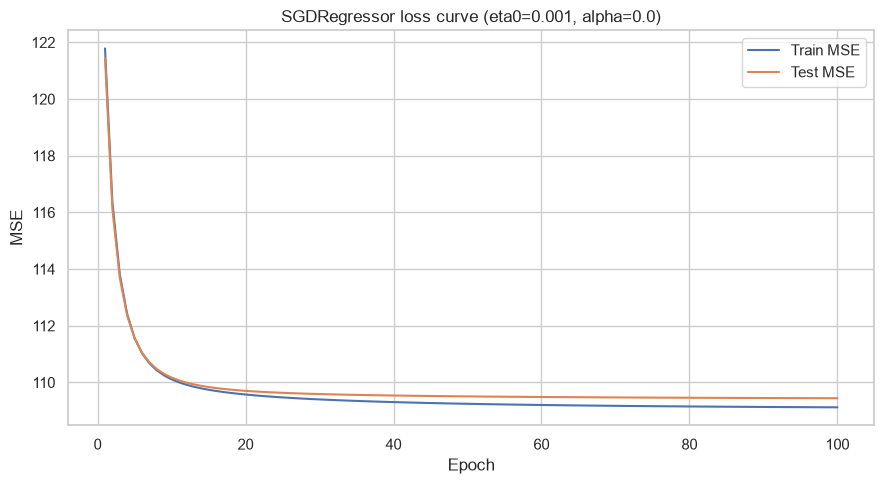

Epoch 1:  train MSE 121.79 | test MSE 121.46
Epoch 100: train MSE 109.12 | test MSE 109.44


In [22]:
sgd_tuned = SGDRegressor(loss="squared_error", penalty="l2", learning_rate="constant",
                         eta0=best_eta0, alpha=best_alpha, random_state=RANDOM_STATE)

train_losses, test_losses = [], []
for epoch in range(best_epochs):
    sgd_tuned.partial_fit(X_train_prep, y_train)   # one pass over the training data
    train_losses.append(mean_squared_error(y_train, sgd_tuned.predict(X_train_prep)))
    test_losses.append(mean_squared_error(y_test, sgd_tuned.predict(X_test_prep)))

epochs_axis = range(1, best_epochs + 1)
plt.figure(figsize=(9, 5))
plt.plot(epochs_axis, train_losses, label="Train MSE")
plt.plot(epochs_axis, test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(f"SGDRegressor loss curve (eta0={best_eta0}, alpha={best_alpha})")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Epoch 1:  train MSE {train_losses[0]:.2f} | test MSE {test_losses[0]:.2f}")
print(f"Epoch {best_epochs}: train MSE {train_losses[-1]:.2f} | test MSE {test_losses[-1]:.2f}")

**What it shows:** Both curves fall steeply during the first ~10 epochs, as gradient descent moves the weights towards the minimum, then flatten out at about 109 to 110. The train and test curves stay right next to each other the whole time (final train 109.1 vs test 109.4), so the model **is not overfitting**: it does as well on unseen data as on the data it learned from.

**What I decided because of it:** Training longer would not help, since the curve is flat after about 40 epochs. The limit is the model type, not the training. The tuned SGD (test MSE 109.4) ends essentially level with the closed-form linear regression (108.8) and with the untuned SGD from Section 4 (109.2). A lower loss needs a model that can learn non-linear combinations, such as the random forest.

### Plots 8 and 9: Scatter plot before and after fitting a regression line

The brief asks for the feature **most correlated with the target**. After cleaning, that feature is `incident_code_MFDV` (the bus is on diversion, correlation 0.54, Plot 5). It is a 0/1 feature, so the points form two columns. I add a small random horizontal jitter so the density is visible; the jitter is only for display.

For the "after" plot I fit a **one-feature `LinearRegression`** on the training set, used only for this plot.

Correlation of incident_code_MFDV with Min Delay (train): 0.540


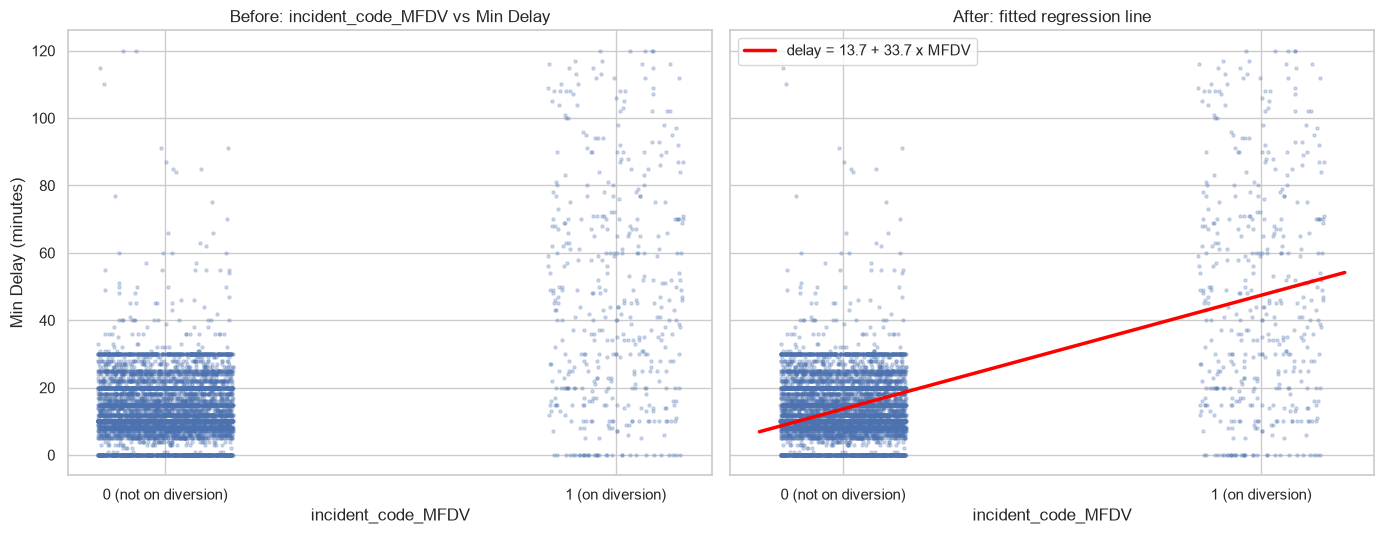

Intercept: 13.67 min | slope: 33.75 min


In [23]:
best_feature = "incident_code_MFDV"
x_feat = (X_train["incident_code"] == "MFDV").astype(int).to_numpy()
print(f"Correlation of {best_feature} with Min Delay (train): {np.corrcoef(x_feat, y_train)[0, 1]:.3f}")

rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(x_feat), 8000, replace=False)
jitter = rng.uniform(-0.15, 0.15, size=len(idx))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

# BEFORE: raw relationship
axes[0].scatter(x_feat[idx] + jitter, y_train.to_numpy()[idx], s=5, alpha=0.25)
axes[0].set_title(f"Before: {best_feature} vs Min Delay")

# AFTER: same scatter + one-feature linear regression line
one_feature_lr = LinearRegression().fit(x_feat.reshape(-1, 1), y_train)
x_line = np.linspace(-0.2, 1.2, 50)
axes[1].scatter(x_feat[idx] + jitter, y_train.to_numpy()[idx], s=5, alpha=0.25)
axes[1].plot(x_line, one_feature_lr.predict(x_line.reshape(-1, 1)), color="red", lw=2.5,
             label=f"delay = {one_feature_lr.intercept_:.1f} + {one_feature_lr.coef_[0]:.1f} x MFDV")
axes[1].set_title(f"After: fitted regression line")
axes[1].legend(loc="upper left")

for ax in axes:
    ax.set_xticks([0, 1], ["0 (not on diversion)", "1 (on diversion)"])
    ax.set_xlabel(best_feature)
axes[0].set_ylabel("Min Delay (minutes)")
plt.tight_layout()
plt.show()

print(f"Intercept: {one_feature_lr.intercept_:.2f} min | slope: {one_feature_lr.coef_[0]:.2f} min")

**What it shows:** Before the line is drawn, the two columns already look very different: trips not on diversion cluster between 0 and 30 minutes, while diverted trips spread from 0 up to 120 minutes. After fitting, the one-feature model is **delay = 13.7 + 33.7 x MFDV**: a bus that is not on diversion is predicted at 13.7 minutes late, and a diversion adds about **34 minutes**, giving 47.4. For a 0/1 feature, the fitted line simply passes through the average delay of each group.

**What I decided because of it:** The line captures the biggest single effect in the data, but the wide spread inside each column (especially for diversions) shows that one feature leaves most of the variation unexplained. That is why the full models use all 8 features. It also explains why the error stays around 10 minutes: diversions vary hugely in length, and the dataset does not say how long or how serious a diversion is.

## 6. Final comparison of the four models

The final table uses the **tuned** `SGDRegressor` from Section 5 together with the other three models from Section 4. All four are scored on the **same test set** with MSE.

In [24]:
final_models = {
    "SGDRegressor (tuned, gradient descent)": sgd_tuned,
    "LinearRegression (closed form)": models["LinearRegression (closed form)"],
    "DecisionTreeRegressor": models["DecisionTreeRegressor"],
    "RandomForestRegressor": models["RandomForestRegressor"],
}

rows = []
for name, model in final_models.items():
    rows.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, model.predict(X_train_prep)),
        "Test MSE": mean_squared_error(y_test, model.predict(X_test_prep)),
    })
comparison = pd.DataFrame(rows).set_index("Model").sort_values("Test MSE")
comparison["Test RMSE (min)"] = np.sqrt(comparison["Test MSE"])

best_name = comparison.index[0]
best_model = final_models[best_name]
print(f"Baseline (always predict the mean): test MSE = {baseline_mse:.2f}")
print(f"Best model (lowest test MSE): {best_name}")
comparison.round(2)

Baseline (always predict the mean): test MSE = 198.42
Best model (lowest test MSE): RandomForestRegressor


,Train MSE,Test MSE,Test RMSE (min)
Model,,,
RandomForestRegressor,101.47,107.86,10.39
LinearRegression (closed form),108.58,108.83,10.43
"SGDRegressor (tuned, gradient descent)",109.12,109.44,10.46
DecisionTreeRegressor,109.91,114.02,10.68


### Plot 10: Train vs test MSE of the four models

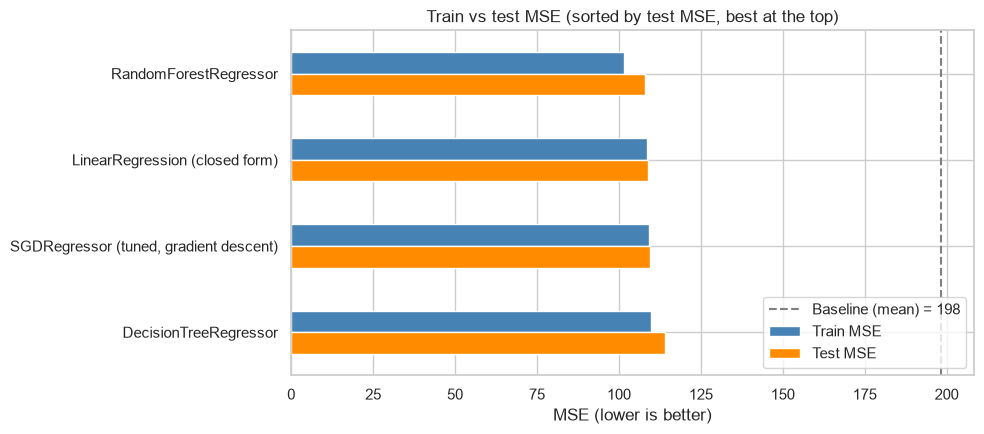

In [25]:
ax = comparison[["Train MSE", "Test MSE"]].plot.barh(figsize=(10, 4.5), color=["steelblue", "darkorange"])
ax.axvline(baseline_mse, color="gray", ls="--", label=f"Baseline (mean) = {baseline_mse:.0f}")
ax.set_xlabel("MSE (lower is better)")
ax.set_ylabel("")
ax.set_title("Train vs test MSE (sorted by test MSE, best at the top)")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Best model: **RandomForestRegressor** (lowest test MSE = 107.86)

| Model | Train MSE | Test MSE | Test RMSE (min) |
|---|---|---|---|
| **RandomForestRegressor** | 101.47 | **107.86** | 10.39 |
| LinearRegression (closed form) | 108.58 | 108.83 | 10.43 |
| SGDRegressor (tuned) | 109.12 | 109.44 | 10.46 |
| DecisionTreeRegressor | 109.91 | 114.02 | 10.68 |
| *Baseline: always predict the mean* | | *198.42* | *14.09* |

**How the dataset affected each model:**
- **Linear models (SGD and closed form):** The data is driven by one strong 0/1 effect (a diversion adds about 34 minutes) plus many small effects of route and time. A linear model handles this well as a sum of shifts, so both linear models do surprisingly well (about 109). They cannot model combinations of features, though, and with train MSE almost equal to test MSE they are limited by bias, not overfitting. SGD reaches the same result as the closed-form solution after tuning, which confirms the gradient descent works correctly.
- **Decision tree:** Weakest on the test set (114.0). After one-hot encoding there are 292 mostly-zero columns, so each split can only separate one route or one code at a time. A single tree is also sensitive to noise in this data, where the same route, code and hour can produce delays from 0 to 100+ minutes.
- **Random forest:** Averages 100 trees, each grown on a different random sample of rows and features. This cancels most of the single tree's noise and lets it pick up some non-linear combinations (for example time of day together with incident type) that the linear models miss. That makes it the best on unseen data.

**Why the random forest is the right choice for this problem:** It has the lowest test MSE, which is the selection rule, and its train/test gap (101.5 vs 107.9) shows only mild overfitting. Its margin over linear regression is small (about 1 MSE), because much of a delay depends on things not in the dataset (traffic, weather, how serious the incident is), so every model hits a floor of about 10 minutes of error. For a schedule platform, a small but consistent gain on unseen trips is what matters, and the forest also copes better with new combinations of route, time and incident. One trade-off: unlike SGD, it cannot be updated incrementally with `partial_fit`, so in the API, retraining refits it on the original data plus the new rows.

## 7. Saving the best model

I save the best model **together with its preprocessing** as one scikit-learn `Pipeline`:
1. `preprocess`: one-hot encoding for the categorical columns and `StandardScaler` for the numeric ones
2. `model`: the best regressor

The pipeline is refitted on the same training set, so it gives exactly the same predictions as above, but it now accepts **raw values** (for example `direction="N"`, `incident_code="MFDV"`). This is what the API needs. It is saved with `joblib` to `summative/API/best_model.pkl`.

I also export the cleaned dataset to `summative/API/training_data.csv`. The API's `/retrain` route needs the original data so it can refit the model on the original rows plus the newly uploaded ones.

In [26]:
import os
import joblib
from sklearn.pipeline import Pipeline

best_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(best_model)),
])
best_pipeline.fit(X_train, y_train)

# sanity check: the pipeline reproduces the test MSE from the comparison table
pipeline_test_mse = mean_squared_error(y_test, best_pipeline.predict(X_test))
print(f"Pipeline test MSE: {pipeline_test_mse:.2f} (table: {comparison.loc[best_name, 'Test MSE']:.2f})")

API_DIR = os.path.join("..", "API")
MODEL_PATH = os.path.join(API_DIR, "best_model.pkl")
joblib.dump(best_pipeline, MODEL_PATH, compress=3)
data.to_csv(os.path.join(API_DIR, "training_data.csv"), index=False)

print(f"Saved model to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")
print(f"Saved training data ({len(data):,} rows) to {os.path.join(API_DIR, 'training_data.csv')}")

Pipeline test MSE: 107.86 (table: 107.86)


Saved model to ../API/best_model.pkl (6.2 MB)
Saved training data (81,967 rows) to ../API/training_data.csv


## 8. Loading the saved model and predicting

`predict_delay` loads the saved pipeline and predicts the delay for **one trip**. It takes the 6 values a user would type into the app (route, direction, incident code, hour, day of week, month) and computes the two derived features (`is_weekend`, `is_night`) itself, exactly as in Section 2.3. The API in Task 2 reuses this function.

In [27]:
def add_derived_features(frame):
    """Add is_weekend and is_night, computed the same way as in Section 2.3."""
    frame = frame.copy()
    frame["is_weekend"] = (frame["day_of_week"] >= 5).astype(int)
    frame["is_night"] = ((frame["hour"] >= 21) | (frame["hour"] < 5)).astype(int)
    return frame


def predict_delay(route_number, direction, incident_code, hour, day_of_week, month,
                  model_path=MODEL_PATH):
    """Load the saved pipeline and predict the bus delay in minutes for one trip."""
    pipeline = joblib.load(model_path)
    row = pd.DataFrame([{
        "route_number": route_number,
        "direction": direction,
        "incident_code": incident_code,
        "hour": hour,
        "day_of_week": day_of_week,
        "month": month,
    }])
    row = add_derived_features(row)[FEATURES]
    prediction = float(pipeline.predict(row)[0])
    return round(max(prediction, 0.0), 2)   # a delay cannot be negative

In [28]:
# predict one row of the TEST set with the saved model
sample = X_test.iloc[0]
actual = y_test.iloc[0]

predicted = predict_delay(
    route_number=int(sample["route_number"]),
    direction=sample["direction"],
    incident_code=sample["incident_code"],
    hour=int(sample["hour"]),
    day_of_week=int(sample["day_of_week"]),
    month=int(sample["month"]),
)

print("Input (one row of the test set):")
print(sample[["route_number", "direction", "incident_code", "hour", "day_of_week", "month"]].to_string())
print(f"\nPredicted delay: {predicted} minutes")
print(f"Actual delay:    {actual} minutes")

Input (one row of the test set):
route_number     113
direction          W
incident_code    TFO
hour              21
day_of_week        6
month             10

Predicted delay: 20.48 minutes
Actual delay:    44 minutes


In [29]:
# a few more test rows, to see the model across different incident types
examples = X_test.groupby("incident_code").head(1).head(6)
for idx, r in examples.iterrows():
    p = predict_delay(int(r["route_number"]), r["direction"], r["incident_code"],
                      int(r["hour"]), int(r["day_of_week"]), int(r["month"]))
    print(f"route {r['route_number']:>3} {r['direction']} {r['incident_code']:<6} "
          f"hour {r['hour']:>2} -> predicted {p:5.1f} min | actual {y_test.loc[idx]:>3} min")

route 113 W TFO    hour 21 -> predicted  20.5 min | actual  44 min
route  54 E TFOI   hour 15 -> predicted   9.2 min | actual   0 min


route  41 S TFPD   hour 11 -> predicted   9.9 min | actual  10 min


route  41 N EFO    hour 15 -> predicted  10.4 min | actual   8 min


route  32 E EFRA   hour  7 -> predicted  10.6 min | actual   8 min
route 999 N SFDP   hour  2 -> predicted   5.7 min | actual   0 min
